# FinGuard Analytics | MLflow Credit Default Pipeline
**Task 35 · Mahmoud Ramadan**

حل عملي لتسجيل دورة تدريب موديل تصنيف تعثّر السداد باستخدام **MLflow + SQLite + Model Registry**.

**المدخل:** الداتا الإلزامية من [Kaggle](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset). **المخرج:** Baseline، خمس تجارب Nested، ROC artifact، موديل مسجّل و`@champion`، وجدول توقعات.

> مشروع تعليمي فقط. `validation_status=approved` و`fair_lending_audit=passed` وسوم محاكاة حسب التكليف، وليست نتائج تدقيق أو تصريح باستخدام حقيقي. اختيار الموديل على test set يطابق التكليف، لكنه يجعل التقييم متفائلًا؛ للاستخدام الحقيقي يلزم validation/CV وholdout مستقل.

## 1 — Install dependencies
شغّل الخلية دي أول مرة. لو المكتبات كانت محمّلة بإصدارات أخرى، أعد تشغيل الـKernel/Runtime مرة واحدة ثم ابدأ من الاستيراد.

In [1]:
%pip install -q mlflow==2.22.2 SQLAlchemy==2.0.43 scikit-learn==1.6.1 pandas==2.2.3 numpy==2.2.6 matplotlib==3.10.3 kagglehub==0.3.13

Note: you may need to restart the kernel to use updated packages.


## 2 — Imports and reproducible configuration
Backend metadata تروح لـSQLite، والملفات الكبيرة تروح إلى مجلد artifacts منفصل. نثبت seed=42، ونستخدم 23 predictor بعد إسقاط ID. ملاحظة: عمود PAY_1 غير موجود؛ الأسماء الفعلية هي PAY_0 وPAY_2 إلى PAY_6.

In [2]:
from __future__ import annotations

import argparse
import hashlib
import json
import logging
import os
from pathlib import Path
import platform
import sys
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

DATASET = "uciml/default-of-credit-card-clients-dataset"
TARGET = "default.payment.next.month"
EXPERIMENT = "credit-default-risk"
REGISTERED_MODEL = "CreditDefaultRiskClassifier"
TRACKING_URI = "sqlite:///mlflow_finguard.db"
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]
FEATURES = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", "PAY_0"]
            + [f"PAY_{i}" for i in range(2, 7)]
            + [f"BILL_AMT{i}" for i in range(1, 7)]
            + [f"PAY_AMT{i}" for i in range(1, 7)])




## 3 — Ingestion, validation, and stratified split
نمنع القيم الناقصة/غير الرقمية/غير المحدودة بدل ما نغير البيانات بصمت. التقسيم 80/20 مع stratification للحفاظ على نسب الفئات.

In [3]:
def resolve_data(data_path=None):
    if data_path:
        path = Path(data_path).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(f"Dataset not found: {path}")
        return path
    local = Path("data/UCI_Credit_Card.csv")
    if local.is_file():
        return local.resolve()
    import kagglehub
    try:
        folder = Path(kagglehub.dataset_download(DATASET))
        matches = list(folder.rglob("UCI_Credit_Card.csv"))
        if len(matches) != 1:
            raise FileNotFoundError(f"Expected one UCI_Credit_Card.csv, found {len(matches)}")
        return matches[0].resolve()
    except Exception as exc:
        raise RuntimeError(
            "Kaggle download failed. Download the required dataset from "
            f"https://www.kaggle.com/datasets/{DATASET}, then pass --data PATH. "
            "No synthetic or alternative dataset is substituted."
        ) from exc


def prepare_data(path):
    frame = pd.read_csv(path)
    print(f"Dataset source: https://www.kaggle.com/datasets/{DATASET}")
    print(f"Dataset file: {path}")
    print(f"Ingested dimensions: {frame.shape[0]} rows x {frame.shape[1]} columns")
    print("Schema:\n" + frame.dtypes.to_string())
    expected = set(FEATURES + ["ID", TARGET])
    if set(frame.columns) != expected:
        raise ValueError(f"Schema mismatch. Missing={expected-set(frame.columns)}, "
                         f"extra={set(frame.columns)-expected}")
    target_numeric = pd.to_numeric(frame[TARGET], errors="raise")
    if target_numeric.isna().any() or set(target_numeric.unique()) != {0, 1}:
        raise ValueError("Target must contain both binary labels 0 and 1 without nulls.")
    y = target_numeric.astype("int64")
    # ID is deliberately excluded. Preserve the exact training column order.
    X = frame.drop(columns=["ID", TARGET]).loc[:, FEATURES]
    X = X.apply(pd.to_numeric, errors="raise").astype("float64")
    null_count = int(X.isna().sum().sum())
    print(f"Feature null count: {null_count}")
    if null_count or not np.isfinite(X.to_numpy()).all():
        raise ValueError("Features contain null or non-finite values; repair source data first.")
    balance = y.value_counts().sort_index().rename("count").to_frame()
    balance["percent"] = balance["count"] / len(y) * 100
    print("Class balance (1 = default):\n" + balance.to_string())
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42)
    print(f"Train/test shapes: {X_train.shape} / {X_test.shape}")
    print("Predictors: " + ", ".join(FEATURES))
    print("Note: this dataset has PAY_0 and PAY_2..PAY_6; there is no PAY_1 column.")
    return frame, X_train, X_test, y_train, y_test


## 4 — Train-only scaling and manual metrics
الـScaler بيتعلم من train فقط. حفظه مع Logistic Regression داخل Pipeline يمنع اختلاف preprocessing وقت inference. ROC-AUC يتحسب من probabilities؛ باقي المقاييس من labels بعتبة 0.5.

In [4]:
def fit_pipeline(C, X_train, y_train):
    # Keep preprocessing in the logged model so alias inference accepts RAW rows.
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(C=C, max_iter=500, solver="lbfgs",
                                          random_state=42)),
    ])
    with warnings.catch_warnings(record=True) as observed:
        warnings.simplefilter("always", ConvergenceWarning)
        pipe.fit(X_train, y_train)
    if any(issubclass(w.category, ConvergenceWarning) for w in observed):
        raise RuntimeError(f"LogisticRegression failed to converge for C={C}.")
    return pipe


def evaluate(pipe, X_test, y_test):
    predicted = pipe.predict(X_test)
    probability = pipe.predict_proba(X_test)[:, 1]
    return {
        "accuracy": float(accuracy_score(y_test, predicted)),
        "precision": float(precision_score(y_test, predicted, zero_division=0)),
        "recall": float(recall_score(y_test, predicted, zero_division=0)),
        "f1_score": float(f1_score(y_test, predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, probability)),
    }


def log_configuration(C, phase, dataset_hash):
    # Manual logging, intentionally no autologging.
    for key, value in {"C": C, "max_iter": 500, "solver": "lbfgs"}.items():
        mlflow.log_param(key, value)
    mlflow.log_params({"random_state": 42, "test_size": 0.2,
                       "threshold": 0.5, "scaler": "StandardScaler"})
    mlflow.set_tag("model_family", "LogisticRegression")
    mlflow.set_tag("pipeline_phase", phase)
    mlflow.set_tags({"dataset_source": DATASET, "dataset_sha256": dataset_hash,
                     "purpose": "coursework_demo", "selection_split": "test_per_assignment"})


## 5 — Tracked lifecycle and registry
الـBaseline يسجل params/tags/metrics وROC. الـParent يحتوي خمس Child runs. نختار فقط أبناء التشغيل الحالي باستخدام filter، ثم أعلى ROC-AUC، مع F1 كعامل ثانوي لكسر التعادل. نحفظ signature على raw float inputs ونحمّل نفس الـPipeline بالـalias.

In [5]:
def run_pipeline(data_path=None, work_dir="."):
    # Every relative backend/artifact path belongs to this chosen project folder.
    path = resolve_data(data_path)
    work = Path(work_dir).expanduser().resolve()
    work.mkdir(parents=True, exist_ok=True)
    previous_cwd = Path.cwd()
    os.chdir(work)
    try:
        return _execute(path, work)
    finally:
        os.chdir(previous_cwd)


def _execute(path, work):
    print("FinGuard Analytics - Task 35 / educational MLflow lifecycle")
    print(f"Python={platform.python_version()} | MLflow={mlflow.__version__} | "
          f"scikit-learn={sklearn.__version__} | pandas={pd.__version__}")
    if mlflow.active_run() is not None:
        raise RuntimeError("End the active MLflow run before starting this pipeline.")
    mlflow.set_tracking_uri(TRACKING_URI)
    mlflow.set_registry_uri(TRACKING_URI)
    client = MlflowClient()
    artifacts = work / "mlartifacts"
    artifacts.mkdir(exist_ok=True)
    experiment = client.get_experiment_by_name(EXPERIMENT)
    if experiment is None:
        experiment_id = client.create_experiment(EXPERIMENT,
                                                 artifact_location=artifacts.as_uri())
    else:
        if experiment.lifecycle_stage != "active":
            raise RuntimeError("Restore the deleted experiment before rerunning.")
        experiment_id = experiment.experiment_id
    mlflow.set_experiment(EXPERIMENT)
    print(f"Tracking/registry URI: {TRACKING_URI}")
    print(f"Experiment: {EXPERIMENT} (ID={experiment_id})")
    print(f"Separate artifact root: {client.get_experiment(experiment_id).artifact_location}")
    frame, X_train, X_test, y_train, y_test = prepare_data(path)
    dataset_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    results_dir = work / "results"
    results_dir.mkdir(exist_ok=True)

    with mlflow.start_run(run_name="logistic-regression-baseline") as baseline_run:
        log_configuration(0.1, "Baseline", dataset_hash)
        baseline = fit_pipeline(0.1, X_train, y_train)
        baseline_metrics = evaluate(baseline, X_test, y_test)
        for key, value in baseline_metrics.items():
            mlflow.log_metric(key, value)
        fig, ax = plt.subplots(figsize=(7, 5))
        RocCurveDisplay.from_estimator(baseline, X_test, y_test, ax=ax,
                                       name="Baseline Logistic Regression")
        ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
        ax.set_title("Credit Default - Baseline ROC Curve")
        ax.legend(loc="lower right")
        fig.tight_layout()
        roc_path = results_dir / "baseline_roc_curve.png"
        fig.savefig(roc_path, dpi=160)
        plt.close(fig)
        mlflow.log_artifact(str(roc_path), artifact_path="diagnostics")
        mlflow.log_dict({"features": FEATURES, "target": TARGET,
                         "dataset_sha256": dataset_hash}, "schema.json")
        print(f"\nBASELINE Run ID: {baseline_run.info.run_id}")
        print(json.dumps(baseline_metrics, indent=2))

    trials = []
    with mlflow.start_run(run_name="logistic-regression-grid-search") as parent:
        parent_id = parent.info.run_id
        mlflow.set_tags({"pipeline_phase": "GridSearch", "purpose": "coursework_demo"})
        mlflow.log_param("C_grid", json.dumps(C_GRID))
        print(f"\nPARENT Run ID: {parent_id}")
        for C in C_GRID:
            with mlflow.start_run(run_name=f"trial_C_{C}", nested=True) as child:
                log_configuration(C, "Trial", dataset_hash)
                pipe = fit_pipeline(C, X_train, y_train)
                metrics = evaluate(pipe, X_test, y_test)
                mlflow.log_metrics(metrics)
                signature = infer_signature(X_train.head(10), pipe.predict(X_train.head(10)))
                mlflow.sklearn.log_model(
                    sk_model=pipe, artifact_path="model", signature=signature,
                    input_example=X_train.head(5),
                    pip_requirements=[f"mlflow=={mlflow.__version__}",
                                      f"scikit-learn=={sklearn.__version__}",
                                      f"pandas=={pd.__version__}", f"numpy=={np.__version__}"],
                )
                trials.append({"C": C, "run_id": child.info.run_id, **metrics})
                print(f"CHILD C={C:<6} Run ID={child.info.run_id} "
                      f"F1={metrics['f1_score']:.6f} ROC-AUC={metrics['roc_auc']:.6f} "
                      f"accuracy={metrics['accuracy']:.6f}")
        best_f1 = max(item["f1_score"] for item in trials)
        mlflow.log_metric("best_f1_score", best_f1)
        print(f"Parent best_f1_score: {best_f1:.6f}")

    # Restrict selection to successful children of THIS parent, excluding stale runs.
    filter_string = (f"tags.mlflow.parentRunId = '{parent_id}' "
                     "AND tags.pipeline_phase = 'Trial' AND attributes.status = 'FINISHED'")
    champions = client.search_runs(
        experiment_ids=[experiment_id], filter_string=filter_string,
        order_by=["metrics.roc_auc DESC", "metrics.f1_score DESC", "params.C ASC"],
        max_results=5,
    )
    if len(champions) != len(C_GRID):
        raise RuntimeError("Expected exactly five successful child trials.")
    champion = champions[0]
    champion_run_id = champion.info.run_id
    print("\nSelection filter: " + filter_string)
    print(f"Champion chosen by ROC-AUC: Run ID={champion_run_id}, "
          f"C={champion.data.params['C']}, ROC-AUC={champion.data.metrics['roc_auc']:.6f}")
    model_version = mlflow.register_model(
        model_uri=f"runs:/{champion_run_id}/model", name=REGISTERED_MODEL,
        await_registration_for=120)
    version = str(model_version.version)
    client.set_registered_model_alias(REGISTERED_MODEL, "champion", version)
    # Requested labels are SIMULATED coursework metadata, not audited findings.
    version_tags = {
        "validation_status": "approved", "fair_lending_audit": "passed",
        "governance_scope": "simulated_coursework_only",
        "real_regulatory_approval": "not_assessed",
        "real_fair_lending_audit": "not_performed",
        "deployment_authorized": "false",
    }
    for key, value in version_tags.items():
        client.set_model_version_tag(REGISTERED_MODEL, version, key, value)
    client.update_model_version(
        REGISTERED_MODEL, version,
        description="Coursework demonstration. Approved/passed tags are simulated assignment "
                    "labels; no regulatory compliance or fair-lending audit was performed. "
                    "Not authorized for real credit decisions.")
    print(f"REGISTERED: {REGISTERED_MODEL}, version={version}, alias=@champion")
    print("Governance tags: " + json.dumps(version_tags))

    alias_uri = f"models:/{REGISTERED_MODEL}@champion"
    production_model = mlflow.pyfunc.load_model(alias_uri)
    sample = X_test.head(5).copy()  # RAW float features; scaler is inside the model.
    predicted = np.asarray(production_model.predict(sample)).astype(int)
    direct = mlflow.sklearn.load_model(f"runs:/{champion_run_id}/model").predict(sample)
    np.testing.assert_array_equal(predicted, direct)
    resolved = client.get_model_version_by_alias(REGISTERED_MODEL, "champion")
    assert str(resolved.version) == version
    verification = pd.DataFrame({"sample_index": sample.index,
                                  "ground_truth": y_test.loc[sample.index].to_numpy(),
                                  "predicted": predicted})
    verification["correct"] = verification.ground_truth == verification.predicted
    print(f"\nAlias inference: {alias_uri}")
    print(verification.to_string(index=False))
    print("Verified: alias version matches registration; alias predictions match logged pipeline.")
    print("LIMITATION: assignment selects on the test set; scores are selection-biased. "
          "Use validation/CV plus an untouched holdout before any real deployment.")
    print("GOVERNANCE: approved/passed are simulated labels only; no actual compliance "
          "or fair-lending audit has been performed.")
    summary = {
        "dataset_shape": list(frame.shape), "dataset_sha256": dataset_hash,
        "baseline_run_id": baseline_run.info.run_id, "baseline_metrics": baseline_metrics,
        "parent_run_id": parent_id, "best_f1_score": best_f1,
        "champion_run_id": champion_run_id, "champion_C": champion.data.params["C"],
        "registered_model": REGISTERED_MODEL, "version": version, "alias_uri": alias_uri,
        "governance_tags": version_tags,
    }
    pd.DataFrame(trials).to_csv(results_dir / "trial_summary.csv", index=False)
    verification.to_csv(results_dir / "alias_predictions.csv", index=False)
    (results_dir / "run_summary.json").write_text(json.dumps(summary, indent=2))
    print(f"\nResults saved under: {results_dir}")
    print("UI command (run from the project folder):")
    print("python -m mlflow ui --backend-store-uri sqlite:///mlflow_finguard.db --port 5000")
    return summary


## 6 — Execute the complete task
- لو فتحت الحزمة الكاملة، الداتا موجودة في `data/UCI_Credit_Card.csv`.
- لو فتحت الـNotebook لوحده في Colab، سيحاول تنزيلها بـ`kagglehub`.
- لو Kaggle طلب تسجيل دخول أو فشل التنزيل، ارفع CSV من المصدر المحدد ثم ضع مساره في `DATA_PATH`. لا ترسل مفاتيح حسابك في الشات.

الخلية تحفظ كمان سجل التنفيذ المطلوب في `execution_log.txt`. كل إعادة تشغيل تنتج runs جديدة ونسخة مسجلة جديدة؛ alias ينتقل لنسخة التشغيل الحالي.

In [6]:
from contextlib import redirect_stdout
import io

DATA_PATH = None  # Or set a local path, e.g. "data/UCI_Credit_Card.csv"
WORK_DIR = "."

class Tee(io.TextIOBase):
    def __init__(self, *streams):
        self.streams = streams
    def write(self, text):
        for stream in self.streams:
            stream.write(text)
            stream.flush()
        return len(text)
    def flush(self):
        for stream in self.streams:
            stream.flush()

log_path = Path(WORK_DIR).resolve() / "execution_log.txt"
with log_path.open("w", encoding="utf-8") as logfile:
    with redirect_stdout(Tee(sys.stdout, logfile)):
        summary = run_pipeline(DATA_PATH, WORK_DIR)
summary

FinGuard Analytics - Task 35 / educational MLflow lifecycle
Python=3.12.14 | MLflow=2.22.2 | scikit-learn=1.6.1 | pandas=2.2.3
Tracking/registry URI: sqlite:///mlflow_finguard.db
Experiment: credit-default-risk (ID=1)
Separate artifact root: file:///workspace/scratch/aa93f546fc9e/output/task35/mlartifacts
Dataset source: https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset
Dataset file: /workspace/scratch/aa93f546fc9e/output/task35/data/UCI_Credit_Card.csv
Ingested dimensions: 30000 rows x 25 columns
Schema:
ID                              int64
LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_A

Registered model 'CreditDefaultRiskClassifier' already exists. Creating a new version of this model...
Created version '2' of model 'CreditDefaultRiskClassifier'.


## 7 — Review the recorded artifacts and alias predictions
الأرقام والجداول التالية ناتجة عن التشغيل، وليست أمثلة ثابتة.

,C,run_id,accuracy,precision,recall,f1_score,roc_auc
0,0.001,820e0e99a40a4795973ec50e51784ca0,0.802333,0.707965,0.180859,0.288115,0.703263
1,0.010,b273283a104948b6b8655a60184b663b,0.807000,0.688196,0.232856,0.347973,0.706750
2,0.100,c16a3a7f33134efd86010e4a7a4f26dc,0.807667,0.687636,0.238885,0.354586,0.707463
3,1.000,97d38de9c6184bdb8bf1eec89fb678fb,0.807667,0.686825,0.239638,0.355307,0.707636
4,10.000,6218d42af8024c3eb21b9c2aab7f8e9e,0.807500,0.685345,0.239638,0.355109,0.707658


,sample_index,ground_truth,predicted,correct
0,6907,0,0,True
1,24575,0,0,True
2,26766,0,0,True
3,2156,1,0,False
4,3179,0,0,True


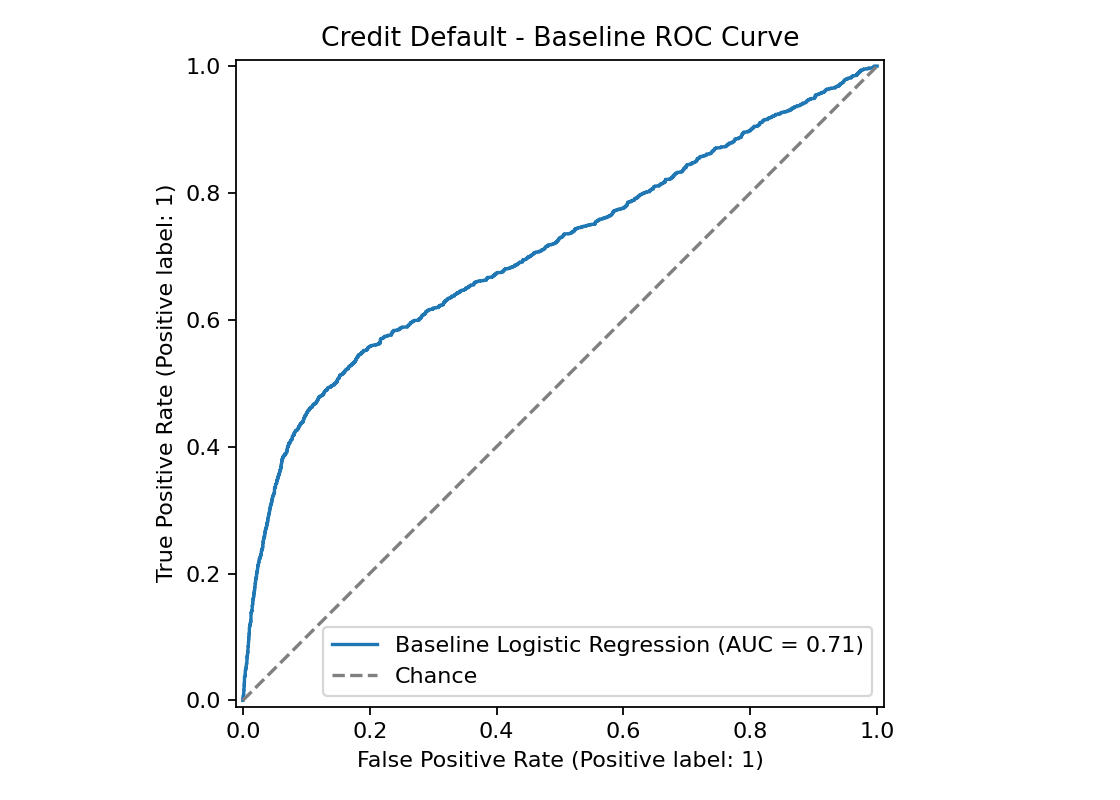

In [7]:
from IPython.display import display, Image
results = Path(WORK_DIR).resolve() / "results"
display(pd.read_csv(results / "trial_summary.csv"))
display(pd.read_csv(results / "alias_predictions.csv"))
display(Image(filename=str(results / "baseline_roc_curve.png")))

## 8 — Inspect MLflow locally
من نفس فولدر المشروع، افتح Terminal وشغّل:
```bash
python -m mlflow ui --backend-store-uri sqlite:///mlflow_finguard.db --port 5000
```
ثم افتح `http://127.0.0.1:5000` على نفس الجهاز. SQLite URI في السكربت يستخدم الـlocal backend مباشرة؛ أمر UI اختياري لعرض التجارب والـRegistry، وليس خدمة منفصلة لازمة لتنفيذ التدريب. في Colab، مخرجات الـNotebook وسجل التنفيذ كافية لمراجعة التكليف؛ عنوان localhost خاص ببيئة Colab.

### Generated files
- `mlflow_finguard.db`: parameters, metrics, tags, lineage, and registry metadata.
- `mlartifacts/`: serialized pipelines, environments, signatures, ROC image.
- `results/`: trial CSV, alias prediction CSV, summary JSON, and ROC PNG.
- `execution_log.txt`: actual printed execution evidence.

### Interpretation and limits
القيمة 1 تعني default. قارن Recall/F1 مع Accuracy لأن الفئات غير متوازنة. استخدام SEX/AGE وبقية الأعمدة يطابق التكليف، لكنه لا يثبت عدالة الموديل. لا توجد معايرة احتمالات أو مراجعة قانونية أو تدقيق fair lending في هذا الحل.

### References
- [Required Kaggle dataset](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset)
- [MLflow model registry and aliases](https://mlflow.org/docs/latest/ml/model-registry/workflow/)
- [MLflow scikit-learn model logging](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html)